# Instacart Reorder Prediction & Top-K Recommendation

**End-to-end machine learning project | Python · pandas · scikit-learn**

## Project overview
This notebook predicts whether a customer will reorder a product in their next training order and ranks previously purchased products for each customer.

### Business objective
Help an online grocery platform surface relevant products, reduce search friction, and support repeat purchases.

### Workflow
1. Load and validate the Instacart Market Basket Analysis data.
2. Explore historical orders and build user–product features from **prior orders only**.
3. Train and evaluate reorder classifiers using a **user-level holdout**.
4. Evaluate ranked recommendations with Precision@K, Recall@K, and Hit Rate@K.
5. Save reproducible artifacts and evaluation results.

> **Important:** The notebook uses the labeled `train` orders for model development. The unlabeled `test` orders are not used to train or evaluate the model. Results are offline estimates, not evidence of production performance.

## 1. Setup and configuration

Place the six original CSV files in `data/raw/`. Do not commit the raw dataset to GitHub unless its license and size make that appropriate. The expected files are listed below.

In [4]:
from pathlib import Path
import json
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("default")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks" and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = Path(os.environ.get("INSTACART_DATA_DIR", PROJECT_ROOT / "data" / "raw")).resolve()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
for directory in (PROCESSED_DIR, MODEL_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

REQUIRED_FILES = [
    "orders.csv",
    "order_products__prior.csv",
    "order_products__train.csv",
    "products.csv",
    "aisles.csv",
    "departments.csv",
]
missing_files = [name for name in REQUIRED_FILES if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Missing files in {DATA_DIR.resolve()}: {missing_files}. "
        "Download the Instacart Market Basket Analysis dataset and place the CSVs in data/raw/."
    )

print("Configuration ready.")
print(f"Data directory: {DATA_DIR.resolve()}")

Configuration ready.
Data directory: /Users/macbook/Downloads/data/raw


## 2. Load and validate source data

Only load columns used by this workflow where practical. We keep `orders.eval_set` to identify the order whose products form the target label.

In [5]:
orders = pd.read_csv(DATA_DIR / "orders.csv")
prior = pd.read_csv(DATA_DIR / "order_products__prior.csv")
train_products = pd.read_csv(DATA_DIR / "order_products__train.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
aisles = pd.read_csv(DATA_DIR / "aisles.csv")
departments = pd.read_csv(DATA_DIR / "departments.csv")

print("orders:", orders.shape)
print("prior products:", prior.shape)
print("labeled train products:", train_products.shape)
print("products:", products.shape)

assert {"order_id", "user_id", "eval_set", "order_number"}.issubset(orders.columns)
assert {"order_id", "product_id", "reordered"}.issubset(prior.columns)
assert {"order_id", "product_id"}.issubset(train_products.columns)
assert orders["order_id"].is_unique, "orders.order_id should be unique."
assert not prior.duplicated(["order_id", "product_id"]).any(), "Duplicate order-product pairs found in prior."

orders: (3421083, 7)
prior products: (32434489, 4)
labeled train products: (1384617, 4)
products: (49688, 4)


## 3. Exploratory data analysis

The EDA below is descriptive. Target labels are inspected separately; they are not used to construct historical predictor features.

,orders
eval_set,
prior,3214874
train,131209
test,75000


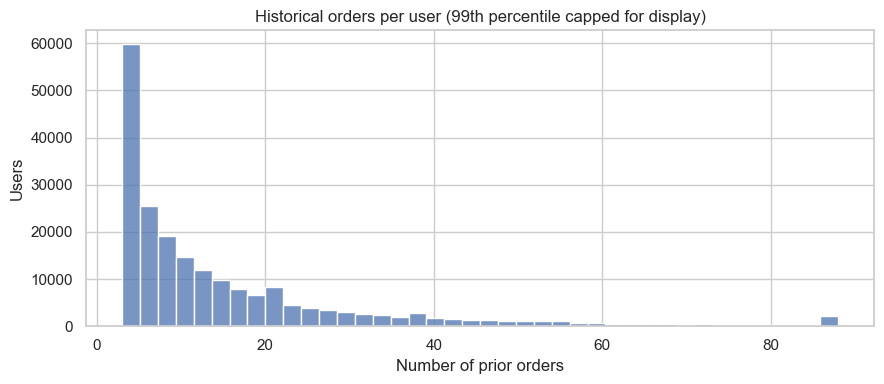

Reordered share among labeled train-order products: 0.599


In [6]:
eval_counts = orders["eval_set"].value_counts(dropna=False).rename_axis("eval_set").to_frame("orders")
display(eval_counts)

user_order_counts = orders.loc[orders["eval_set"].eq("prior")].groupby("user_id")["order_id"].nunique()
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(user_order_counts.clip(upper=user_order_counts.quantile(0.99)), bins=40, ax=ax)
ax.set(title="Historical orders per user (99th percentile capped for display)",
       xlabel="Number of prior orders", ylabel="Users")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "historical_orders_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

target_rate = train_products["reordered"].mean() if "reordered" in train_products else np.nan
print(f"Reordered share among labeled train-order products: {target_rate:.3f}")

## 4. Build leakage-aware user–product features

### Evaluation design
For each user with an `eval_set == "train"` order:
- **Candidate products** are products the user purchased in their `prior` history.
- **Positive label (`target_reordered = 1`)** means that product appears in the user's labeled train order.
- **Negative label (`target_reordered = 0`)** means the previously purchased product does not appear in that train order.

All behavioral features are computed from `order_products__prior.csv` and prior orders only. We intentionally do **not** use user aggregates over every row in `orders.csv`, since that table also contains later train/test order metadata.

In [7]:
# Historical orders only: features must not see the target order or test order.
prior_orders = orders.loc[orders["eval_set"].eq("prior"),
                          ["order_id", "user_id", "order_number", "days_since_prior_order"]].copy()
train_orders = orders.loc[orders["eval_set"].eq("train"), ["order_id", "user_id"]].copy()

prior_history = prior.merge(
    prior_orders[["order_id", "user_id", "order_number", "days_since_prior_order"]],
    on="order_id",
    how="inner",
    validate="many_to_one",
)

# User-level features from prior history only.
user_features = (
    prior_history.groupby("user_id", as_index=False)
    .agg(
        user_prior_order_count=("order_id", "nunique"),
        user_unique_products=("product_id", "nunique"),
        user_prior_item_count=("product_id", "size"),
        user_reorder_rate=("reordered", "mean"),
        user_avg_days_between_orders=("days_since_prior_order", "mean"),
    )
)
basket_sizes = prior_history.groupby(["user_id", "order_id"]).size().rename("basket_size")
user_basket_features = basket_sizes.groupby("user_id").mean().rename("user_avg_basket_size").reset_index()
user_features = user_features.merge(user_basket_features, on="user_id", how="left", validate="one_to_one")

In [8]:
# Product-level features from prior history only.
product_features = (
    prior_history.groupby("product_id", as_index=False)
    .agg(
        product_prior_purchase_count=("order_id", "size"),
        product_unique_users=("user_id", "nunique"),
        product_reorder_rate=("reordered", "mean"),
        product_mean_cart_position=("add_to_cart_order", "mean"),
    )
)

# User-product interaction features from prior history only.
user_product_features = (
    prior_history.groupby(["user_id", "product_id"], as_index=False)
    .agg(
        up_prior_purchase_count=("order_id", "nunique"),
        up_prior_reorder_count=("reordered", "sum"),
        up_mean_cart_position=("add_to_cart_order", "mean"),
        up_last_order_number=("order_number", "max"),
    )
)
last_prior_order = prior_orders.groupby("user_id", as_index=False)["order_number"].max()
last_prior_order = last_prior_order.rename(columns={"order_number": "user_last_prior_order_number"})
user_product_features = user_product_features.merge(last_prior_order, on="user_id", how="left", validate="many_to_one")
user_product_features["up_orders_since_last_purchase"] = (
    user_product_features["user_last_prior_order_number"] - user_product_features["up_last_order_number"]
)
user_product_features["up_reorder_rate"] = (
    user_product_features["up_prior_reorder_count"] /
    user_product_features["up_prior_purchase_count"].clip(lower=1)
)

# Target products in the labeled train order, mapped to the corresponding user.
train_labels = (
    train_products[["order_id", "product_id"]]
    .merge(train_orders, on="order_id", how="inner", validate="many_to_one")
    [["user_id", "product_id"]]
    .drop_duplicates()
)
train_labels["target_reordered"] = 1

# Keep only users with a labeled train order and only historical product candidates.
train_user_ids = train_orders["user_id"].unique()
candidates = user_product_features[user_product_features["user_id"].isin(train_user_ids)].copy()
candidates = candidates.merge(
    train_labels, on=["user_id", "product_id"], how="left", validate="one_to_one"
)
candidates["target_reordered"] = candidates["target_reordered"].fillna(0).astype("int8")

# Add descriptive product metadata for recommendation display, not as raw model features.
product_metadata = products[["product_id", "product_name", "aisle_id", "department_id"]].copy()
dataset = (
    candidates
    .merge(user_features, on="user_id", how="left", validate="many_to_one")
    .merge(product_features, on="product_id", how="left", validate="many_to_one")
    .merge(product_metadata, on="product_id", how="left", validate="many_to_one")
)

print("Candidate dataset:", dataset.shape)
print("Users:", dataset["user_id"].nunique())
print("Positive rate:", round(dataset["target_reordered"].mean(), 4))
display(dataset.head())

Candidate dataset: (8474661, 23)
Users: 131209
Positive rate: 0.0978


,user_id,product_id,up_prior_purchase_count,up_prior_reorder_count,up_mean_cart_position,up_last_order_number,user_last_prior_order_number,up_orders_since_last_purchase,up_reorder_rate,target_reordered,user_prior_order_count,user_unique_products,user_prior_item_count,user_reorder_rate,user_avg_days_between_orders,user_avg_basket_size,product_prior_purchase_count,product_unique_users,product_reorder_rate,product_mean_cart_position,product_name,aisle_id,department_id
0,1,196,10,9,1.400000,10,10,0,0.900000,1,10,18,59,0.694915,20.259259,5.9,35791,8000,0.776480,3.721774,Soda,77,7
1,1,10258,9,8,3.333333,10,10,0,0.888889,1,10,18,59,0.694915,20.259259,5.9,1946,557,0.713772,4.277492,Pistachios,117,19
2,1,10326,1,0,5.000000,5,10,5,0.000000,0,10,18,59,0.694915,20.259259,5.9,5526,1923,0.652009,4.191097,Organic Fuji Apples,24,4
3,1,12427,10,9,3.300000,10,10,0,0.900000,0,10,18,59,0.694915,20.259259,5.9,6476,1679,0.740735,4.760037,Original Beef Jerky,23,19
4,1,13032,3,2,6.333333,10,10,0,0.666667,1,10,18,59,0.694915,20.259259,5.9,3751,1286,0.657158,5.622767,Cinnamon Toast Crunch,121,14


## 5. Data quality checks and persist the modeling table

The modeling table has one row per user–product candidate. User and product IDs are identifiers, not numeric predictors; they are excluded from the feature matrix.

In [9]:
assert not dataset.duplicated(["user_id", "product_id"]).any(), "Expected one row per user-product candidate."
assert dataset["target_reordered"].isin([0, 1]).all()
assert dataset["target_reordered"].notna().all()

target_summary = dataset["target_reordered"].value_counts().rename_axis("target").to_frame("rows")
display(target_summary)

dataset.to_csv(PROCESSED_DIR / "candidate_features.csv", index=False)
print(f"Saved: {PROCESSED_DIR / 'candidate_features.csv'}")

,rows
target,
0,7645837
1,828824


Saved: /Users/macbook/Downloads/data/processed/candidate_features.csv


## 6. Train/test split by user

A random row split can put products from the same customer in both train and test sets, making offline evaluation overly optimistic. Here, users are split first, so every candidate for a user belongs to a single partition.

The imputer and scaler are fitted inside a scikit-learn `Pipeline` on the training partition only.

In [10]:
NON_FEATURE_COLUMNS = {
    "user_id", "product_id", "product_name", "aisle_id", "department_id",
    "target_reordered", "up_last_order_number", "user_last_prior_order_number"
}
feature_cols = [
    col for col in dataset.select_dtypes(include=np.number).columns
    if col not in NON_FEATURE_COLUMNS
]
if not feature_cols:
    raise ValueError("No numeric model features were selected.")

all_users = dataset["user_id"].drop_duplicates().to_numpy()
train_user_ids_split, test_user_ids_split = train_test_split(
    all_users, test_size=0.2, random_state=RANDOM_STATE
)
train_mask = dataset["user_id"].isin(train_user_ids_split)
test_mask = dataset["user_id"].isin(test_user_ids_split)

X_train = dataset.loc[train_mask, feature_cols]
y_train = dataset.loc[train_mask, "target_reordered"]
X_test = dataset.loc[test_mask, feature_cols]
y_test = dataset.loc[test_mask, "target_reordered"]

print(f"Features ({len(feature_cols)}): {feature_cols}")
print(f"Train candidates: {len(X_train):,}; test candidates: {len(X_test):,}")
print(f"Train users: {len(train_user_ids_split):,}; test users: {len(test_user_ids_split):,}")
print(f"Train positive rate: {y_train.mean():.4f}; test positive rate: {y_test.mean():.4f}")

Features (15): ['up_prior_purchase_count', 'up_prior_reorder_count', 'up_mean_cart_position', 'up_orders_since_last_purchase', 'up_reorder_rate', 'user_prior_order_count', 'user_unique_products', 'user_prior_item_count', 'user_reorder_rate', 'user_avg_days_between_orders', 'user_avg_basket_size', 'product_prior_purchase_count', 'product_unique_users', 'product_reorder_rate', 'product_mean_cart_position']
Train candidates: 6,777,721; test candidates: 1,696,940
Train users: 104,967; test users: 26,242
Train positive rate: 0.0979; test positive rate: 0.0973


## 7. Train a baseline model

Logistic regression is a strong, interpretable baseline for this binary classification task. `class_weight="balanced"` compensates for class imbalance during fitting. The reported metrics are calculated on held-out users.

In [11]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        solver="lbfgs",
    )),
])

start_time = time.perf_counter()
model.fit(X_train, y_train)
training_seconds = time.perf_counter() - start_time

test_probability = model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.5).astype("int8")

metrics = {
    "roc_auc": roc_auc_score(y_test, test_probability),
    "pr_auc": average_precision_score(y_test, test_probability),
    "precision_at_threshold_0_5": precision_score(y_test, test_prediction, zero_division=0),
    "recall_at_threshold_0_5": recall_score(y_test, test_prediction, zero_division=0),
    "f1_at_threshold_0_5": f1_score(y_test, test_prediction, zero_division=0),
    "training_seconds": training_seconds,
}
display(pd.DataFrame([metrics]).round(4))
print(classification_report(y_test, test_prediction, zero_division=0))

,roc_auc,pr_auc,precision_at_threshold_0_5,recall_at_threshold_0_5,f1_at_threshold_0_5,training_seconds
0,0.8186,0.3687,0.2301,0.751,0.3523,35.2227


              precision    recall  f1-score   support

           0       0.96      0.73      0.83   1531784
           1       0.23      0.75      0.35    165156

    accuracy                           0.73   1696940
   macro avg       0.60      0.74      0.59   1696940
weighted avg       0.89      0.73      0.78   1696940



## 8. Classification diagnostics

ROC-AUC and average precision summarize ranking quality across thresholds. The confusion matrix uses a 0.5 probability threshold for illustration; that threshold is not automatically optimal for business use.

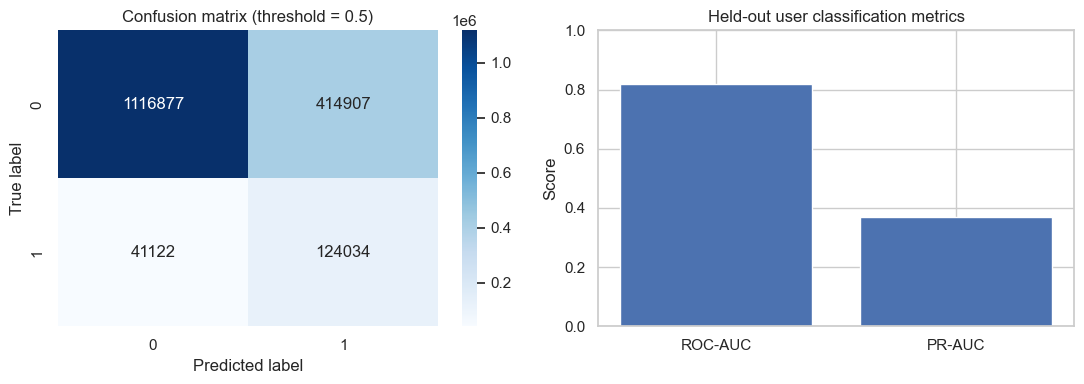

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set(title="Confusion matrix (threshold = 0.5)",
            xlabel="Predicted label", ylabel="True label")

axes[1].bar(["ROC-AUC", "PR-AUC"], [metrics["roc_auc"], metrics["pr_auc"]])
axes[1].set_ylim(0, 1)
axes[1].set(title="Held-out user classification metrics", ylabel="Score")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "classification_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Evaluate Top-K recommendations

For each held-out user, rank candidate products by predicted probability. `Precision@K` is the share of the top-K recommendations that appear in the labeled train order; `Recall@K` is the share of that user's positive labels recovered in the top K; `Hit Rate@K` indicates whether at least one relevant product appears in the top K.

Metrics are averaged across users with at least one candidate. K values larger than a user's candidate count are clipped to the available number of candidates for precision calculation.

,K,Precision@K,Recall@K,Hit Rate@K,Users evaluated
0,3,0.4177,0.2660,0.7238,26242
1,5,0.3694,0.3657,0.7981,26242
2,10,0.2961,0.5291,0.8680,26242
3,20,0.2256,0.7041,0.9108,26242


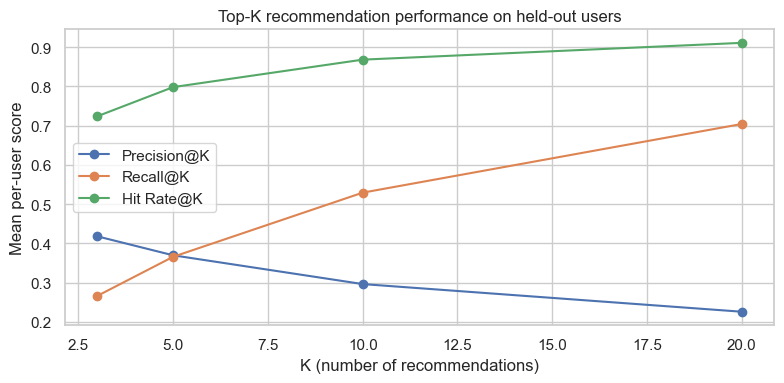

In [13]:
test_results = dataset.loc[test_mask, ["user_id", "product_id", "product_name", "target_reordered"]].copy()
test_results["predicted_probability"] = test_probability
test_results = test_results.sort_values(
    ["user_id", "predicted_probability"], ascending=[True, False]
)

def evaluate_top_k(frame: pd.DataFrame, k_values=(3, 5, 10, 20)) -> pd.DataFrame:
    rows = []
    for k in k_values:
        per_user_precision, per_user_recall, per_user_hit = [], [], []
        for _, group in frame.groupby("user_id", sort=False):
            labels = group["target_reordered"].to_numpy()
            if len(labels) == 0:
                continue
            top_labels = labels[:k]
            relevant_total = int(labels.sum())
            precision = float(top_labels.sum() / min(k, len(labels)))
            recall = float(top_labels.sum() / relevant_total) if relevant_total else 0.0
            hit = float(top_labels.sum() > 0)
            per_user_precision.append(precision)
            per_user_recall.append(recall)
            per_user_hit.append(hit)
        rows.append({
            "K": k,
            "Precision@K": np.mean(per_user_precision) if per_user_precision else np.nan,
            "Recall@K": np.mean(per_user_recall) if per_user_recall else np.nan,
            "Hit Rate@K": np.mean(per_user_hit) if per_user_hit else np.nan,
            "Users evaluated": len(per_user_precision),
        })
    return pd.DataFrame(rows)

ranking_metrics = evaluate_top_k(test_results)
display(ranking_metrics.round(4))
ranking_metrics.to_csv(PROCESSED_DIR / "ranking_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
for metric_name in ["Precision@K", "Recall@K", "Hit Rate@K"]:
    ax.plot(ranking_metrics["K"], ranking_metrics[metric_name], marker="o", label=metric_name)
ax.set(title="Top-K recommendation performance on held-out users",
       xlabel="K (number of recommendations)", ylabel="Mean per-user score")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "top_k_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Inspect recommendations for a held-out user

This is a qualitative example, not a substitute for aggregate ranking metrics. The displayed probabilities are model scores and should not be interpreted as calibrated purchase probabilities without a separate calibration analysis.

In [14]:
example_user = int(test_results["user_id"].iloc[0])
example_recommendations = (
    test_results.loc[test_results["user_id"].eq(example_user)]
    .head(10)
    [["product_id", "product_name", "predicted_probability", "target_reordered"]]
    .reset_index(drop=True)
)
print(f"Example held-out user: {example_user}")
display(example_recommendations)

Example held-out user: 1


,product_id,product_name,predicted_probability,target_reordered
0,196,Soda,0.911448,1
1,12427,Original Beef Jerky,0.899688,0
2,10258,Pistachios,0.889471,1
3,25133,Organic String Cheese,0.882174,1
4,46149,Zero Calorie Cola,0.852242,1
5,13032,Cinnamon Toast Crunch,0.792562,1
6,49235,Organic Half & Half,0.784334,1
7,13176,Bag of Organic Bananas,0.753518,0
8,38928,0% Greek Strained Yogurt,0.680890,1
9,39657,Milk Chocolate Almonds,0.651130,1


## 11. Save model, feature schema, and metrics

Persist the full preprocessing/model pipeline, not just the classifier, so inference uses the same imputation and scaling steps. The artifact can be loaded later with compatible library versions.

In [15]:
joblib.dump(model, MODEL_DIR / "reorder_pipeline.joblib")
with open(MODEL_DIR / "feature_columns.json", "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, indent=2)

with open(PROCESSED_DIR / "classification_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

test_results.to_csv(PROCESSED_DIR / "heldout_user_predictions.csv", index=False)
print("Saved model pipeline, feature schema, metrics, and held-out predictions.")

Saved model pipeline, feature schema, metrics, and held-out predictions.


## 12. Conclusions and limitations

### What this project demonstrates
- Leakage-aware feature engineering from historical transactions.
- User-level holdout validation to reduce customer overlap between train and test partitions.
- Classification evaluation with ROC-AUC, PR-AUC, precision, recall, and F1.
- Top-K ranking evaluation for a recommendation use case.
- Reproducible model artifacts and generated reports.

### Limitations
- The notebook evaluates the labeled `train` orders; it does not score the competition's unlabeled `test` orders.
- Candidate products are limited to products observed in a user's prior history. This is appropriate for **reorder** prediction, but it cannot recommend genuinely new products.
- A random user holdout estimates generalization to unseen users in this dataset; it is not a chronological production backtest.
- Offline metrics do not establish causal business impact. An online A/B test would be required for that.
- Full-dataset execution can require substantial RAM and runtime.

### Next steps
1. Add a chronological backtest with order-level snapshots.
2. Compare against a popularity and per-user reorder-rate baseline.
3. Tune the ranking objective and probability threshold on a validation split, not on the final test set.
4. Add experiment tracking and automated tests for data contracts.